 # Task 5 - Confronto fra ordinamento naturale e nested dissection prova con N = 32, 64, 128,256, 512, 1024
 Questo notebook contiene degli esperimenti che intendono confrontare l'ordinamento naturale e nested dissection. In particolare verrà effettuato un confronto dei tempi, del numero degli elementi non nulli, e i grafici della soluzione al variare dei valori di N= 32, 64, 128, 256, 512, 1024.

## Esecuzione Task 1

In [15]:
from pathlib import Path
import subprocess

N_scelto = 512
ricomincia_progetto = Path("..").resolve()
cartella_task1 = ricomincia_progetto / "task1"

risultato = subprocess.run(
    [str(cartella_task1 / "main")],
    input=f"{N_scelto}\n",
    text=True,
    cwd=cartella_task1,
    capture_output=True
)

print(risultato.stdout)

Inserisci il numero di punti interni per lato N: Numero totale di nodi interni: 262144
Passo della griglia h: 0.00194932
File coords.txt creato.
File connectivity.txt creato.



## Esecuzione Task 2 

In [16]:
cartella_task2 = ricomincia_progetto / "task2"

risultato_task2 = subprocess.run(
    [str(cartella_task2 / "main")],
    text=True,
    cwd=cartella_task2,
    capture_output=True
)

print(risultato_task2.stdout)

Ho letto 262144 nodi.
File ordering.txt creato.



## Esecuzione task 3 - input 0 naturale

In [17]:
import numpy as np
from scipy.sparse import csc_matrix

cartella_task3 = ricomincia_progetto / "task3"

risultato_task3 = subprocess.run(
    [str(cartella_task3 / "main")],
    input="0\n",
    text=True,
    cwd=cartella_task3,
    capture_output=True
)

print(risultato_task3.stdout)

Ho letto 262144 nodi.
Scegli l'ordinamento:
0 - ordinamento naturale
1 - ordinamento di ordering.txt
File A.txt creato.
File rhs.txt creato.



Caricamento in python dei risultati ottenuti dall'ordinamento naturale

In [18]:
dati_A_naturale = np.loadtxt(cartella_task3 / "A.txt")
rhs_naturale = np.loadtxt(cartella_task3 / "rhs.txt")

righe = dati_A_naturale[:, 0].astype(int)
colonne = dati_A_naturale[:, 1].astype(int)
valori = dati_A_naturale[:, 2]

numero_nodi = rhs_naturale.size

A_naturale = csc_matrix(
    (valori, (righe, colonne)),
    shape=(numero_nodi, numero_nodi)
)

print("Dimensioni di A:", A_naturale.shape)
print("Elementi non nulli di A:", A_naturale.nnz)
print("Dimensione di rhs:", rhs_naturale.size)

Dimensioni di A: (262144, 262144)
Elementi non nulli di A: 1308672
Dimensione di rhs: 262144


## Esecuzione Task 3 - input 1 usando ordering.txt

In [19]:
risultato_task3 = subprocess.run(
    [str(cartella_task3 / "main")],
    input="1\n",
    text=True,
    cwd=cartella_task3,
    capture_output=True
)

print(risultato_task3.stdout)

Ho letto 262144 nodi.
Scegli l'ordinamento:
0 - ordinamento naturale
1 - ordinamento di ordering.txt
File A.txt creato.
File rhs.txt creato.



Caricamento su python dei dati ottenuti dall'ordinamento nested dissection

In [20]:
dati_A_riordinata = np.loadtxt(cartella_task3 / "A.txt")
rhs_riordinata = np.loadtxt(cartella_task3 / "rhs.txt")

righe_riordinate = dati_A_riordinata[:, 0].astype(int)
colonne_riordinate = dati_A_riordinata[:, 1].astype(int)
valori_riordinati = dati_A_riordinata[:, 2]

A_riordinata = csc_matrix(
    (
        valori_riordinati,
        (righe_riordinate, colonne_riordinate)
    ),
    shape=(numero_nodi, numero_nodi)
)

print("Dimensioni di A riordinata:", A_riordinata.shape)
print("Elementi non nulli:", A_riordinata.nnz)

Dimensioni di A riordinata: (262144, 262144)
Elementi non nulli: 1308672


## Fattorizzazione di Cholesky 
- caso con ordinamento naturale.

In [21]:
from time import perf_counter
from sksparse.cholmod import cholesky

inizio = perf_counter()

fattore_naturale = cholesky(-A_naturale, ordering_method="natural")

fine = perf_counter()

tempo_naturale = fine - inizio
L_naturale = fattore_naturale.L()

print("Tempo di fattorizzazione naturale:", tempo_naturale, "secondi")
print("Elementi non nulli di L naturale:", L_naturale.nnz)

Tempo di fattorizzazione naturale: 5.243746083113365 secondi
Elementi non nulli di L naturale: 141290515


- caso nested dissection

In [22]:
inizio = perf_counter()

fattore_riordinato = cholesky(
    -A_riordinata,
    ordering_method="natural"
)

fine = perf_counter()

tempo_riordinato = fine - inizio
L_riordinata = fattore_riordinato.L()

print(
    "Tempo di fattorizzazione nested dissection:",
    tempo_riordinato,
    "secondi"
)

print(
    "Elementi non nulli di L riordinata:",
    L_riordinata.nnz
)

Tempo di fattorizzazione nested dissection: 0.46474229195155203 secondi
Elementi non nulli di L riordinata: 14064628


## Confronto fra le due fattorizzazioni nel caso naturale e nested dissection

In [23]:
print(f"Confronto per N = {N_scelto}")
print()
print("Naturale:")
print("  tempo di fattorizzazione naturale =", tempo_naturale)
print("  elementi di L =", L_naturale.nnz)
print()
print("Nested dissection:")
print("  tempo di fattorizzazione nested dissection =", tempo_riordinato)
print("  elementi di L =", L_riordinata.nnz)

Confronto per N = 512

Naturale:
  tempo di fattorizzazione naturale = 5.243746083113365
  elementi di L = 141290515

Nested dissection:
  tempo di fattorizzazione nested dissection = 0.46474229195155203
  elementi di L = 14064628


## Tempo impiegato nel calcolo di u e calcolo del residuo nel caso di ordinamento naturale:

In [24]:
from scipy.sparse.linalg import spsolve_triangular

inizio = perf_counter()
#calcolo di y
y_naturale = spsolve_triangular(
    L_naturale,
    -rhs_naturale,
    lower=True
)
#calcolo di u
u_naturale = spsolve_triangular(
    L_naturale.T,
    y_naturale,
    lower=False
)

fine = perf_counter()

tempo_soluzione_naturale = fine - inizio

residuo_naturale = (
    A_naturale @ u_naturale
    - rhs_naturale
)

residuo_relativo_naturale = (
    np.linalg.norm(residuo_naturale)
    / np.linalg.norm(rhs_naturale)
)

print("Tempo per risolvere naturale:", tempo_soluzione_naturale)
print("Residuo relativo naturale:", residuo_relativo_naturale)

Tempo per risolvere naturale: 20.05158695904538
Residuo relativo naturale: 6.199827182036687e-12


## Tempo impiegato nel calcolo di u e calcolo del residuo per la matrice nested Dissection:

In [25]:
inizio = perf_counter()

y_riordinata = spsolve_triangular(
    L_riordinata,
    -rhs_riordinata,
    lower=True
)

u_riordinata = spsolve_triangular(
    L_riordinata.T,
    y_riordinata,
    lower=False
)

fine = perf_counter()

tempo_soluzione_riordinata = fine - inizio

residuo_riordinato = (
    A_riordinata @ u_riordinata
    - rhs_riordinata
)

residuo_relativo_riordinato = (
    np.linalg.norm(residuo_riordinato)
    / np.linalg.norm(rhs_riordinata)
)

print("Tempo per risolvere nested:", tempo_soluzione_riordinata)
print("Residuo relativo nested:", residuo_relativo_riordinato)

Tempo per risolvere nested: 0.9978144589113072
Residuo relativo nested: 3.3978796713164915e-12


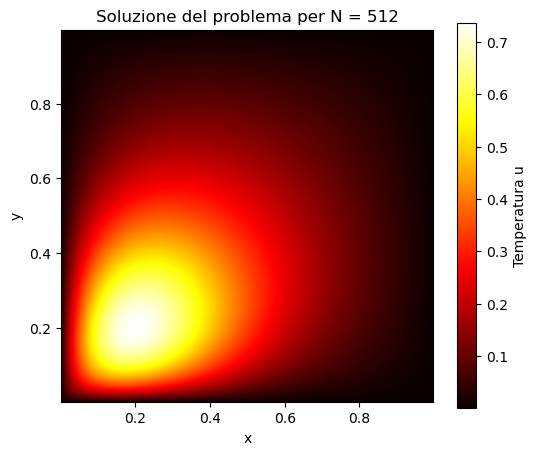

In [26]:
import matplotlib.pyplot as plt

soluzione_griglia = u_naturale.reshape(
    N_scelto,
    N_scelto
)

h = 1.0 / (N_scelto + 1)

plt.figure(figsize=(6, 5))

immagine = plt.imshow(
    soluzione_griglia,
    origin="lower",
    extent=[h, 1.0 - h, h, 1.0 - h],
    cmap="hot"
)

plt.colorbar(immagine, label="Temperatura u")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Soluzione del problema per N = {N_scelto}")

plt.show()

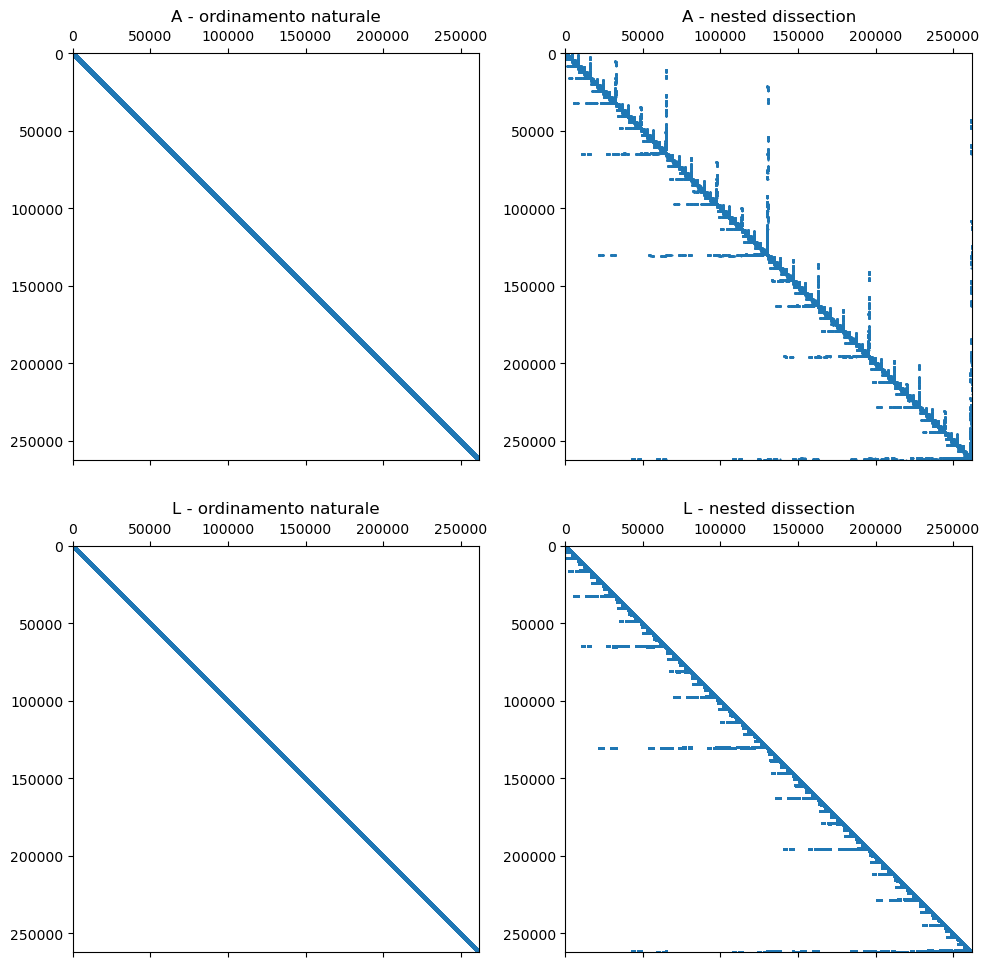

In [27]:
figura, assi = plt.subplots(2, 2, figsize=(10, 10))

assi[0, 0].spy(A_naturale, markersize=0.5)
assi[0, 0].set_title("A - ordinamento naturale")

assi[0, 1].spy(A_riordinata, markersize=0.5)
assi[0, 1].set_title("A - nested dissection")

assi[1, 0].spy(L_naturale, markersize=0.5)
assi[1, 0].set_title("L - ordinamento naturale")

assi[1, 1].spy(L_riordinata, markersize=0.5)
assi[1, 1].set_title("L - nested dissection")

plt.tight_layout()
plt.show()

## Risultati degli esperimenti

| N | Tempo fattorizzazione naturale (s) | Tempo fattorizzazione nested (s) | nnz(L) naturale | nnz(L) nested | Tempo soluzione naturale (s)| Tempo soluzione nested (s) | Residuo naturale | Residuo nested |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 32 | 0.025353 s | 0.006182 s | 32799 | 15998 |0.036709 s | 0.009756 s |1.8443967848443292e-14|1.7021018082150917e-14|
|64| 0.027631 s | 0.004808 s | 292895 | 131140 | 0.029952 s | 0.012401 s | 5.4421581429486317e-14 | 5.1865576251626894e-14 |
| 512 | 6.1737 s | 0.3717 s | 141290515 | 14064628 | 12.0940 s | 2.8628 s | 6.20e-12 | 3.40e-12 |

## Osservazioni e conclusioni 

Dai dati raccolti è possibile trarre le seguenti conclusioni:
1. All'aumentare di N la Nested Dissection diminuisce il fill-in della matrice L è possibile notare come nel caso di N = 32 abbiamo circa il 50% degli elementi non nulli in meno fino addirittura al 90% nel caso di N = 512. 
2. Questo permette a sua volta al programma di accelerare la fattorizzazione risultando subito 4 volte più veloce del caso naturale in caso di N=32 fno a 16 volte più veloce nel caso N = 512.
3. La precisione dell'esperimento non cambia molto fra i due casi e al crescere di N, entrambe le soluzioni sono numericamente accetabili. Questo è in accordo con il fatto che il riordinamento infatti, non cambia il problema matematico ma cambia solo l'ordine delle incognite per rendere la fattorizzazione più efficiente.